# 🏗️ 01 · Architecture and Parameter Counting

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 1 of 6
> Course notes: the 4-3-3-2 network with **35 params** (page 3) and the 4-5-3-2 network with **51 params** (page 7, "Memory footprint of FFNN")

Module 01 showed that one neuron draws one line, and that a **layer** of sigmoid neurons can bend the boundary (XOR). Before training such networks we need to be able to *describe* them. This notebook answers the first practical question about any network:

> **"Looking at a list of layer sizes such as `[784, 128, 64, 10]`, how many numbers does the network have to learn, how much memory do they take, and how much compute does one pass cost?"**

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | What "fully connected / dense / feed-forward" means |
| 2 | The formula $\text{params}_l = n_{l-1}\ n_l + n_l$ and *why* |
| 3 | Hand-count the two networks from the notes, then check with code |
| 4 | Where the parameters live in a real network (spoiler: the first layer) |
| 5 | Width vs depth, compute (FLOPs) and activation counts |
| 6 | Sizing a network to a parameter budget |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)

---
## 1 · The variables

### 📖 Notation for the whole of module 02 (same as the course notes)

| Symbol | Shape | Meaning |
|---|---|---|
| $L$ | number | number of layers with weights (hidden + output). The input is "layer 0". |
| $n_l$ | number | number of neurons in layer $l$ ($n_0$ = number of inputs) |
| $\vec x = o^{[0]}$ | $n_0\times1$ | one input example, a **column** vector |
| $w_{ji}$ | number | weight on the wire **from** neuron $i$ (layer $l-1$) **to** neuron $j$ (layer $l$). First index = destination. |
| $W^{[l]}$ | $n_l\times n_{l-1}$ | all weights of layer $l$; **row $j$** = the incoming weights of neuron $j$ (notes: $W^{h1}_{5\times4}$) |
| $b^{[l]}$ | $n_l\times1$ | biases of layer $l$, one per neuron (the weight of the constant input $x_0=1$) |
| $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | $n_l\times1$ | net inputs of layer $l$; entry $j$ is $net_j=\sum_i w_{ji}\ o_i+b_j$ |
| $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ | outputs (activations) of layer $l$; $g$ = activation function, e.g. sigmoid |
| $x_{ji}$ | number | the input that arrives at neuron $j$ from $i$, i.e. $x_{ji}=o_i$ (Mitchell / notes) |
| $t_k$ | number | target for output neuron $k$ |
| $E$ | number | the error (loss) we minimise |
| $\delta_j=-\dfrac{\partial E}{\partial net_j}$ | number | **error term** of neuron $j$ ("how much the error drops if $net_j$ rises") |
| $\eta$ | number | learning rate |
| $N$ | number | batch size; a batch is $X\in\mathbb R^{n_0\times N}$ with **one example per column** |

The notes also name layers by role: $h1$, $h2$ (hidden) and $o$ (output), e.g. $o^{h1}=\sigma(W^{h1}x+b^{h1})$.
For this notebook we only need $L$, $n_l$, $W^{[l]}$ and $b^{[l]}$.

---
## 2 · What is a feed-forward network? 🔀

* **Layers:** neurons are arranged in columns: input layer → hidden layer(s) → output layer.
* **Feed-forward:** information flows only left → right. No loops (loops come later, in RNNs).
* **Fully connected (dense):** every neuron in layer $l$ receives a wire from **every** neuron in layer $l-1$. Each wire has its own weight $w_{ji}$.
* **Bias:** every neuron (not the inputs) also owns one bias $b_j$.

The function below draws any such network from its list of sizes. It is only for pictures; the counting comes next.

In [2]:
# ---------- plotting helper (visualisation only) ----------
def draw_network(ax, sizes, names=None, title="", max_show=8, show_counts=True):
    """Draw a fully-connected network. sizes = [n_0, n_1, ..., n_L]. Large layers are truncated with '⋮'."""
    L = len(sizes)
    xs = np.linspace(0, 1, L)
    pos = []
    for l, n in enumerate(sizes):
        shown = min(n, max_show)
        ys = np.linspace(0.5 + 0.06 * (shown - 1), 0.5 - 0.06 * (shown - 1), shown) if shown > 1 else np.array([0.5])
        pos.append(ys)
    for l in range(L - 1):                                       # wires between consecutive layers
        for ya in pos[l]:
            for yb in pos[l + 1]:
                ax.plot([xs[l], xs[l + 1]], [ya, yb], color=C["grid"], lw=0.8, zorder=1)
    colors = [C["muted"]] + [C["blue"]] * (L - 2) + [C["orange"]]
    for l, ys in enumerate(pos):
        ax.scatter(np.full(len(ys), xs[l]), ys, s=260, color="white", edgecolor=colors[l], linewidth=2.2, zorder=3)
        if sizes[l] > max_show:
            ax.text(xs[l], 0.5 - 0.06 * max_show, "⋮", ha="center", va="top", fontsize=14, color=colors[l])
        label = (names[l] if names else ("input" if l == 0 else "output" if l == L - 1 else f"hidden {l}"))
        ax.text(xs[l], 0.5 + 0.06 * (min(sizes[l], max_show) - 1) + 0.09, f"{label}\n$n_{l}$ = {sizes[l]}",
                ha="center", va="bottom", fontsize=9.5, color=colors[l])
        if show_counts and l > 0:
            w, b = sizes[l - 1] * sizes[l], sizes[l]
            ax.text((xs[l - 1] + xs[l]) / 2, 0.5 - 0.06 * (min(max(sizes), max_show) - 1) - 0.1,
                    f"{sizes[l-1]}×{sizes[l]} = {w} w\n+ {b} b", ha="center", va="top", fontsize=9, color=C["ink"])
    ax.set_xlim(-0.12, 1.12); ax.set_ylim(-0.15, 1.15); ax.axis("off"); ax.set_title(title)

📊 **Plot:** the two networks from the notes. Under each block of wires: weights (w) and biases (b) of that layer.

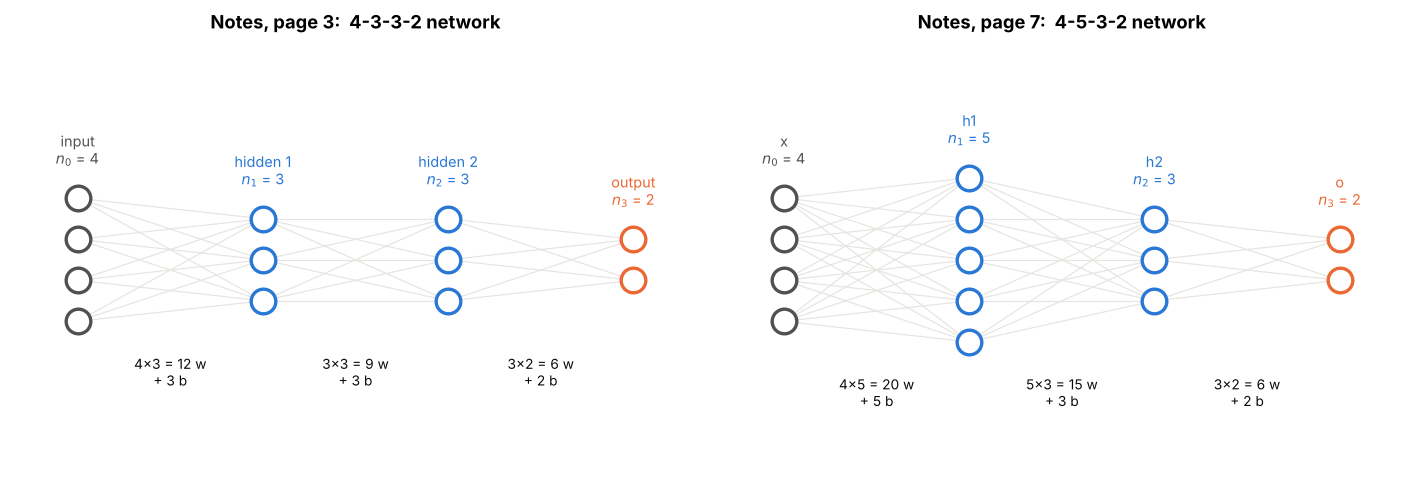

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
draw_network(axs[0], [4, 3, 3, 2], title="Notes, page 3:  4-3-3-2 network")
draw_network(axs[1], [4, 5, 3, 2], names=["x", "h1", "h2", "o"], title="Notes, page 7:  4-5-3-2 network")
plt.tight_layout(); plt.show()

---
## 3 · The counting formula 🧮

Take one layer $l$ with $n_{l-1}$ inputs and $n_l$ neurons.
* Every one of the $n_l$ neurons has a wire from every one of the $n_{l-1}$ inputs → $n_{l-1}\times n_l$ **weights**. They fill the matrix $W^{[l]}$ of shape $n_l\times n_{l-1}$.
* Every neuron has one **bias** → $n_l$ biases, the vector $b^{[l]}$.

$$\boxed{\text{params}_l=\underbrace{n_{l-1}\ n_l}_{\text{weights }W^{[l]}}+\underbrace{n_l}_{\text{biases }b^{[l]}}=n_l\ (n_{l-1}+1)} \qquad\qquad \text{params}=\sum_{l=1}^{L}n_l\ (n_{l-1}+1)$$

The second form has a nice reading: **each neuron owns $n_{l-1}+1$ numbers** (one per incoming wire plus its bias).

### ✍️ By hand: the 4-3-3-2 network (notes, page 3)
| layer | weights | biases | total |
|---|---|---|---|
| 4 → 3 | $4\times3=12$ | 3 | 15 |
| 3 → 3 | $3\times3=9$ | 3 | 12 |
| 3 → 2 | $3\times2=6$ | 2 | 8 |
| **sum** | 27 | 8 | **35** ✅ (the notes: "12 + 9 + 6 = 27, + 8 = 35 params") |

### ✍️ By hand: the 4-5-3-2 network (notes, page 7)
$(20+5)+(15+3)+(6+2)=25+18+8=\mathbf{51}$ – the notes write "51 F.P." (51 floating-point numbers).

Now the same thing in code.

**Step A – the counter.** It walks over consecutive pairs of layer sizes $(n_{l-1}, n_l)$, applies the formula to each pair, and keeps one row of results per layer.

* `range(1, len(sizes))` → layers $l=1..L$ (layer 0 is the input and has no weights)
* `w = n_out * n_in` → $n_{l-1}\ n_l$ entries in $W^{[l]}$ (shape $n_l\times n_{l-1}$)
* `b = n_out` → one bias per neuron

In [4]:
def count_params(sizes):
    """sizes = [n_0 (inputs), n_1, ..., n_L (outputs)]  ->  (list of per-layer dicts, total)."""
    rows, total = [], 0
    for l in range(1, len(sizes)):
        n_in, n_out = sizes[l - 1], sizes[l]
        w = n_out * n_in                  # W^[l] has shape (n_l, n_{l-1})
        b = n_out                         # b^[l] has shape (n_l, 1)
        rows.append(dict(layer=l, W_shape=(n_out, n_in), weights=w, biases=b, total=w + b))
        total += w + b
    return rows, total

**Step B – a pretty printer.** `show` only formats the rows of `count_params` as a table (`:>10,` right-aligns and adds thousands separators). It returns the rows so later cells can reuse them.

In [5]:
def show(sizes):
    """Pretty-print the parameter table of a network."""
    rows, total = count_params(sizes)
    print(f"network {sizes}")
    print(f"{'layer':<7}{'W shape':<13}{'weights':>10}{'biases':>8}{'total':>10}")
    for r in rows:
        print(f"{r['layer']:<7}{str(r['W_shape']):<13}{r['weights']:>10,}{r['biases']:>8,}{r['total']:>10,}")
    print(f"{'TOTAL':<20}{sum(r['weights'] for r in rows):>10,}{sum(r['biases'] for r in rows):>8,}{total:>10,}\n")
    return rows, total

**Step C – the two networks from the notes.** The totals must be 35 and 51.

In [6]:
show([4, 3, 3, 2])
show([4, 5, 3, 2]);

network [4, 3, 3, 2]
layer  W shape         weights  biases     total
1      (3, 4)               12       3        15
2      (3, 3)                9       3        12
3      (2, 3)                6       2         8
TOTAL                       27       8        35

network [4, 5, 3, 2]
layer  W shape         weights  biases     total
1      (5, 4)               20       5        25
2      (3, 5)               15       3        18
3      (2, 3)                6       2         8
TOTAL                       41      10        51



### ✅ Check the formula by actually creating the arrays
If the formula is right, allocating every $W^{[l]}$ and $b^{[l]}$ and counting their entries must give the same number.

**Step A – create the parameters.** For every layer: a weight matrix of shape $(n_l, n_{l-1})$ filled with small random numbers, and a bias column of zeros. The list holds one `(W, b)` pair per layer. (How to choose the random scale is discussed in notebook 04; here only the shapes matter.)

In [7]:
def init_params(sizes, rng):
    """Create W^[l] (n_l × n_{l-1}) and b^[l] (n_l × 1) for every layer, small random weights."""
    return [(rng.normal(0, 0.1, (sizes[l], sizes[l - 1])), np.zeros((sizes[l], 1)))
            for l in range(1, len(sizes))]

**Step B – count the entries and compare.** `.size` is the number of entries of an array. `assert` stops the notebook with an error if the two counts ever disagree.

In [8]:
rng = np.random.default_rng(0)
for sizes in ([4, 3, 3, 2], [4, 5, 3, 2], [784, 128, 64, 10]):
    params = init_params(sizes, rng)
    actual = sum(W.size + b.size for W, b in params)          # .size = number of entries
    print(f"{str(sizes):<20} formula = {count_params(sizes)[1]:>7,}   arrays = {actual:>7,}   shapes = {[W.shape for W, _ in params]}")
    assert actual == count_params(sizes)[1]

[4, 3, 3, 2]         formula =      35   arrays =      35   shapes = [(3, 4), (3, 3), (2, 3)]
[4, 5, 3, 2]         formula =      51   arrays =      51   shapes = [(5, 4), (3, 5), (2, 3)]
[784, 128, 64, 10]   formula = 109,386   arrays = 109,386   shapes = [(128, 784), (64, 128), (10, 64)]


---
## 4 · A realistic network: an MNIST digit classifier 🔢

MNIST images are $28\times28=784$ pixels and there are 10 digits, so a classic network is `[784, 128, 64, 10]`.

In [9]:
sizes = [784, 128, 64, 10]
rows, total = show(sizes)
for r in rows:
    print(f"layer {r['layer']} holds {100 * r['total'] / total:5.1f}% of all parameters")

network [784, 128, 64, 10]
layer  W shape         weights  biases     total
1      (128, 784)      100,352     128   100,480
2      (64, 128)         8,192      64     8,256
3      (10, 64)            640      10       650
TOTAL                  109,184     202   109,386

layer 1 holds  91.9% of all parameters
layer 2 holds   7.5% of all parameters
layer 3 holds   0.6% of all parameters


📊 **Plot:** the network (left, large layers truncated) and each layer's share of the parameters (right).

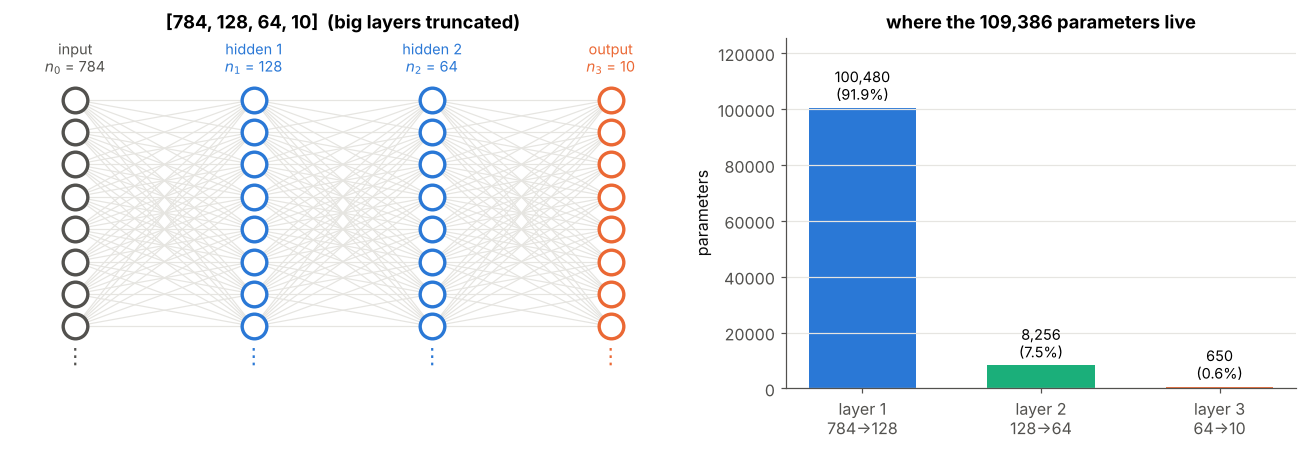

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1.3, 1]))
draw_network(axs[0], sizes, title="[784, 128, 64, 10]  (big layers truncated)", show_counts=False)

names = [f"layer {r['layer']}\n{r['W_shape'][1]}→{r['W_shape'][0]}" for r in rows]
w = np.array([r["weights"] for r in rows]); b = np.array([r["biases"] for r in rows])
bars = axs[1].bar(names, w + b, color=[C["blue"], C["aqua"], C["orange"]], width=0.6)
axs[1].bar_label(bars, labels=[f"{v:,}\n({100 * v / total:.1f}%)" for v in w + b], padding=3, fontsize=9.5)
axs[1].set_ylim(0, 1.25 * (w + b).max()); axs[1].set_ylabel("parameters"); axs[1].grid(axis="x", visible=False)
axs[1].set_title(f"where the {total:,} parameters live")
plt.tight_layout(); plt.show()

**Intuition.** The first layer connects 784 inputs to 128 neurons, so it needs $784\times128\approx100\text{k}$ weights. Later layers are small on both sides. *In fully connected networks on raw high-dimensional input, the first layer dominates* – one reason convolutional layers (which share weights) were invented for images.

---
## 5 · Width vs depth: same input and output, very different budgets 📏

In [11]:
configs = {
    "tiny        784-32-10":          [784, 32, 10],
    "wide        784-512-10":         [784, 512, 10],
    "deep        784-128×4-10":       [784, 128, 128, 128, 128, 10],
    "bottleneck  784-256-32-256-10":  [784, 256, 32, 256, 10],
    "MNIST       784-128-64-10":      [784, 128, 64, 10],
}
totals = {name: count_params(s)[1] for name, s in configs.items()}
for name, t in totals.items():
    print(f"{name:<34}{t:>9,} params   = {4 * t / 1e6:5.2f} MB as float32 (4 bytes each)")

tiny        784-32-10                25,450 params   =  0.10 MB as float32 (4 bytes each)
wide        784-512-10              407,050 params   =  1.63 MB as float32 (4 bytes each)
deep        784-128×4-10            151,306 params   =  0.61 MB as float32 (4 bytes each)
bottleneck  784-256-32-256-10       220,202 params   =  0.88 MB as float32 (4 bytes each)
MNIST       784-128-64-10           109,386 params   =  0.44 MB as float32 (4 bytes each)


📊 **Plot:** the same totals as bars, sorted from smallest to largest.

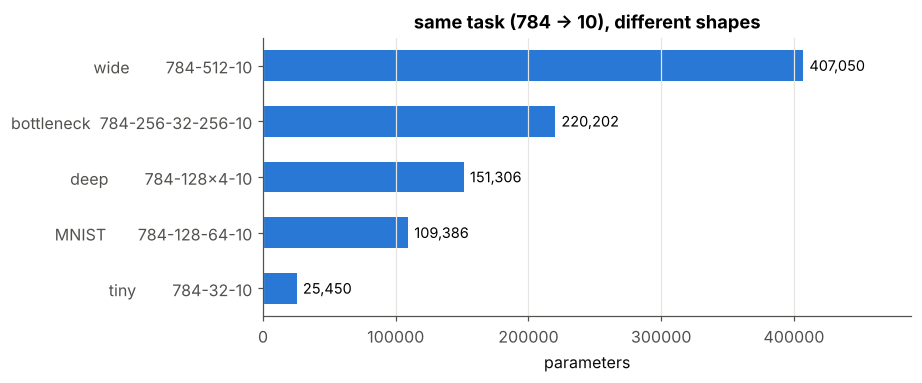

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
order = sorted(totals, key=totals.get)
bars = ax.barh(order, [totals[k] for k in order], color=C["blue"], height=0.55)
ax.bar_label(bars, labels=[f"{totals[k]:,}" for k in order], padding=4, fontsize=9.5)
ax.set_xlim(0, 1.2 * max(totals.values())); ax.set_xlabel("parameters"); ax.grid(axis="y", visible=False)
ax.set_title("same task (784 → 10), different shapes")
plt.tight_layout(); plt.show()

Note the "deep" network has **4 hidden layers** yet fewer parameters than the "wide" one: after the first layer, a $128\to128$ layer only costs $16{,}512$. Depth is cheap; width on a big input is expensive.

---
## 6 · Beyond parameters: compute and activations ⚡

For one example passing forward through layer $l$, neuron $j$ computes $net_j=\sum_i w_{ji}o_i+b_j$: that is $n_{l-1}$ **multiply-accumulates (MACs)**. Over the whole layer: $n_{l-1}\times n_l$ MACs – the same as the weight count! One MAC = 2 floating-point operations (FLOPs).

$$\text{FLOPs per example}\approx 2\sum_l n_{l-1}n_l\qquad\qquad\text{activations to keep for training}=\sum_{l\ge1} n_l\ \ (\text{per example})$$

Activations matter because **backpropagation needs every layer's output again** (notebook 04 and 06).

**The cost function in code:** `macs` sums $n_{l-1}n_l$ over the layers and multiplies by the batch size; `acts` sums $n_l$ over all non-input layers. FLOPs are `2 * macs`.

In [13]:
def forward_cost(sizes, batch=1):
    macs = batch * sum(sizes[l - 1] * sizes[l] for l in range(1, len(sizes)))   # multiply-adds
    acts = batch * sum(sizes[1:])                                               # outputs to store
    return 2 * macs, acts

Evaluate it for the MNIST network at three batch sizes. Both numbers grow **linearly** with the batch size; the parameters do not.

In [14]:
for B in (1, 32, 256):
    flops, acts = forward_cost([784, 128, 64, 10], B)
    print(f"batch = {B:<4} forward FLOPs = {flops:>12,}    activations stored = {acts:>8,}")

batch = 1    forward FLOPs =      218,368    activations stored =      202
batch = 32   forward FLOPs =    6,987,776    activations stored =    6,464
batch = 256  forward FLOPs =   55,902,208    activations stored =   51,712


---
## 7 · Sizing a network to a budget 💰

Suppose you may use at most a given number of parameters. How wide can each hidden layer of a `[784, H, H, 10]` network be?
$\text{params}(H)=785H + (H+1)H + 10(H+1)$ – a quadratic in $H$.

**The search.** Start at $H=1$ and keep increasing $H$ while the *next* width still fits the budget. Simple and exact – the count is cheap to compute, so there is no need to solve the quadratic.

In [15]:
def hidden_width_for_budget(n_in, n_out, budget, n_hidden=2):
    """Largest H such that [n_in] + [H]*n_hidden + [n_out] fits within the budget."""
    H = 1
    while count_params([n_in] + [H + 1] * n_hidden + [n_out])[1] <= budget:
        H += 1
    return H, count_params([n_in] + [H] * n_hidden + [n_out])[1]

**Run it for two budgets**, and also compute the parameter count for every width up to 1200 (for the plot):

In [16]:
budget_results = {}
for budget in (100_000, 1_000_000):
    budget_results[budget] = hidden_width_for_budget(784, 10, budget)
    H, t = budget_results[budget]
    print(f"budget {budget:>9,}  →  H = {H:>4}   ({t:,} params)")

Hs = np.arange(1, 1200)
p = np.array([count_params([784, h, h, 10])[1] for h in Hs])

budget   100,000  →  H =  110   (99,670 params)
budget 1,000,000  →  H =  678   (999,382 params)


📊 **Plot:** parameters vs width (log scale) with each budget and the width it allows.

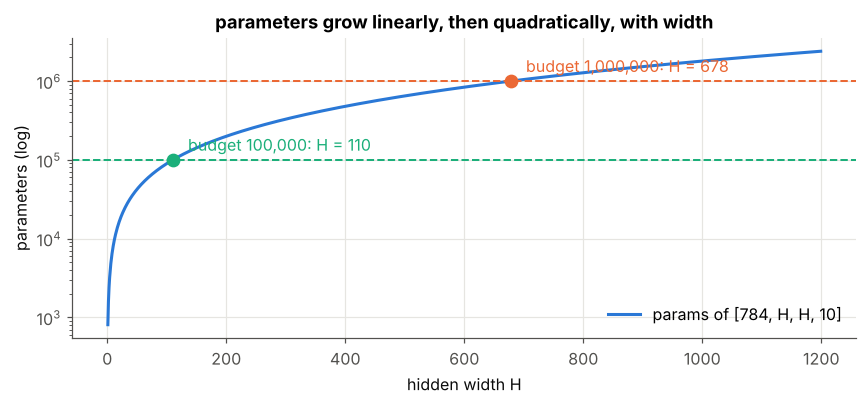

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(Hs, p, color=C["blue"], label="params of [784, H, H, 10]")
for budget, col in [(100_000, C["aqua"]), (1_000_000, C["orange"])]:
    H, t = budget_results[budget]
    ax.axhline(budget, color=col, ls="--", lw=1.3)
    ax.plot(H, t, "o", color=col, ms=8)
    ax.annotate(f"budget {budget:,}: H = {H}", (H, budget), textcoords="offset points", xytext=(10, 6), color=col)
ax.set_yscale("log"); ax.set_xlabel("hidden width H"); ax.set_ylabel("parameters (log)")
ax.set_title("parameters grow linearly, then quadratically, with width"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

---
## 8 · Summary 📌

| Question | Answer |
|---|---|
| params of layer $l$ | $n_{l-1}n_l+n_l=n_l(n_{l-1}+1)$ |
| shape of $W^{[l]}$ / $b^{[l]}$ | $n_l\times n_{l-1}$ / $n_l\times1$ |
| notes' networks | 4-3-3-2 → **35**, 4-5-3-2 → **51** |
| `[784,128,64,10]` | **109,386** params, 92% in layer 1, 0.44 MB in float32 |
| forward FLOPs per example | $\approx 2\times$ number of weights |
| activations kept for backprop | $\sum_l n_l$ per example (× batch size) |

### ✍️ Try it yourself
1. Count `[3072, 512, 256, 100]` (CIFAR-100 on flattened pixels) by hand, then check with `show`.
2. Remove all biases. What fraction of the MNIST network's parameters disappears?
3. The notes' word2vec model (later module) has an input matrix $V_{d\times n}$ and an output matrix $U_{n\times d}$ with **no biases**. Show it has $2dn$ parameters, and compute it for $d=300$, $n=10^5$.
4. Add batch norm (2 learnable numbers per hidden neuron). How many extra parameters for `[784,128,64,10]`?

**Next →** `02 - Matrix-Form Forward Pass`: turn all these weights into one clean matrix computation.